# Non-linear models

Models beyond the 6 linear methods, compared on validation F1:

1. Decision trees and random forest
2. Logistic regression + gradient boosting
3. Ensemble (logistic + forest)
4. Neural network (MLP)

Each part is independent and can be run on its own. Parts 1-3 retrain their models (several minutes each); part 4 reads the saved results in `figures/nn/` unless `RUN_BASELINE = True`.

# Part 1 - Decision trees and random forest
(from `experiments_trees.ipynb`, uses `trees.py`)

In [1]:
"""
Tree-based models on the same features and the same 80/20 split as the
linear models: one decision tree (several depths) and a random forest.
Each model is compared on the validation F1 (best threshold).

Usage: python experiments_trees.py
"""
import time

import numpy as np

from helpers import create_csv_submission
from preprocessing import split_train_val, best_threshold
from preprocessing import build_features   # same features as run.py
from run import load_data
from trees import fit_bins, apply_bins, train_tree, predict_tree, tree_depth, \
    train_forest, predict_forest

MAKE_SUBMISSION = False   # True -> retrain the forest on all data and write a CSV


def accuracy(y_true, probs, t):
    return np.mean((probs >= t).astype(int) == y_true)


# ---------------------------------------------------------------------
# Data: same cleaning + one-hot + interactions as run.py
# ---------------------------------------------------------------------
x_train, x_test, y01, test_ids, names = load_data()
x_train, x_test = build_features(x_train, x_test, names)
y01 = y01.astype(int)
print("Features:", x_train.shape[1])

i_tr, i_val = split_train_val(len(x_train))           # same split as everyone
mean, edges = fit_bins(x_train[i_tr])                 # bins learned on train only
xb_tr = apply_bins(x_train[i_tr], mean, edges)
xb_val = apply_bins(x_train[i_val], mean, edges)
y_tr, y_val = y01[i_tr], y01[i_val]

results = []

# ---------------------------------------------------------------------
# 1. One decision tree, several depths
# ---------------------------------------------------------------------
print("\nDecision tree:")
for depth in [4, 6, 8, 10, 12]:
    t0 = time.time()
    tree = train_tree(xb_tr, y_tr, max_depth=depth, min_leaf=50)
    probs = predict_tree(tree, xb_val)
    t, f = best_threshold(y_val, probs)
    print(f"  max_depth = {depth:>2}  F1 = {f:.4f}  acc = {accuracy(y_val, probs, t):.3f}  "
          f"threshold = {t:.2f}  ({time.time() - t0:.1f}s)")
    results.append((f"tree depth {depth}", f))

# ---------------------------------------------------------------------
# 2. Random forest
# ---------------------------------------------------------------------
FOREST = dict(n_trees=50, max_depth=12, min_leaf=50, max_features="sqrt")
print(f"\nRandom forest {FOREST}:")
t0 = time.time()
forest = train_forest(xb_tr, y_tr, **FOREST)
probs = predict_forest(forest, xb_val)
t_forest, f = best_threshold(y_val, probs)
print(f"  F1 = {f:.4f}  acc = {accuracy(y_val, probs, t_forest):.3f}  "
      f"threshold = {t_forest:.2f}  ({time.time() - t0:.1f}s)")
results.append(("random forest", f))

# ---------------------------------------------------------------------
# Summary
# ---------------------------------------------------------------------
print("\nSummary (validation F1):")
for name, f in sorted(results, key=lambda r: -r[1]):
    print(f"  {name:<18} {f:.4f}")

# ---------------------------------------------------------------------
# Optional: submission with the forest (retrained on all the data)
# ---------------------------------------------------------------------
if MAKE_SUBMISSION:
    mean, edges = fit_bins(x_train)
    forest = train_forest(apply_bins(x_train, mean, edges), y01, **FOREST)
    probs_test = predict_forest(forest, apply_bins(x_test, mean, edges))
    y_pred = np.where(probs_test >= t_forest, 1, -1)
    create_csv_submission(test_ids, y_pred, "submission_forest.csv")
    print(f"submission_forest.csv written, {np.mean(y_pred == 1):.1%} predicted positive")


Features: 207

Decision tree:
  max_depth =  4  F1 = 0.3867  acc = 0.822  threshold = 0.18  (8.7s)
  max_depth =  6  F1 = 0.4053  acc = 0.867  threshold = 0.19  (8.1s)
  max_depth =  8  F1 = 0.4087  acc = 0.864  threshold = 0.20  (10.7s)
  max_depth = 10  F1 = 0.4074  acc = 0.859  threshold = 0.19  (13.3s)
  max_depth = 12  F1 = 0.4003  acc = 0.850  threshold = 0.19  (15.3s)

Random forest {'n_trees': 50, 'max_depth': 12, 'min_leaf': 50, 'max_features': 'sqrt'}:
  10/50 trees
  20/50 trees
  30/50 trees
  40/50 trees
  50/50 trees
  F1 = 0.4258  acc = 0.865  threshold = 0.20  (90.1s)

Summary (validation F1):
  random forest      0.4258
  tree depth 8       0.4087
  tree depth 10      0.4074
  tree depth 6       0.4053
  tree depth 12      0.4003
  tree depth 4       0.3867


Saved figures/tree_depth.pdf and figures/tree_depth.png


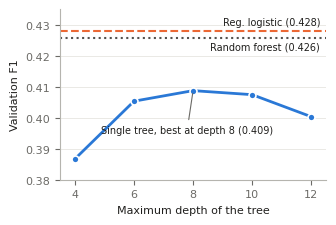

In [2]:
"""
Figure for the report: validation F1 of a single decision tree as a function
of its maximum depth, compared with the random forest and the regularized
logistic regression (same features, same 80/20 split).

The numbers come from experiments_trees.py and run.py.
Usage: python plot_tree_depth.py  -> figures/tree_depth.pdf (+ .png)
"""
import os

import matplotlib.pyplot as plt

# results (validation F1, best threshold)
DEPTHS = [4, 6, 8, 10, 12]
TREE_F1 = [0.3867, 0.4053, 0.4087, 0.4074, 0.4003]
FOREST_F1 = 0.4258       # 50 trees, depth 12, sqrt(D) features per split
LOGISTIC_F1 = 0.4279     # regularized logistic regression (run.py)

# same colors as visualization.ipynb
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
INK, MUTED, GRID = "#1f1e1c", "#6b6a66", "#e6e5e0"

plt.rcParams.update({
    "font.size": 8,
    "axes.edgecolor": "#b5b4ae",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.labelcolor": INK,
})

fig, ax = plt.subplots(figsize=(3.4, 2.3))   # one column of the LaTeX template

# reference models: horizontal lines, labelled directly at the right
ax.axhline(LOGISTIC_F1, color=ORANGE, linewidth=1.5, linestyle="--")
ax.axhline(FOREST_F1, color=GRAY, linewidth=1.5, linestyle=":")
ax.text(12.3, LOGISTIC_F1 + 0.0012, f"Reg. logistic ({LOGISTIC_F1:.3f})",
        ha="right", va="bottom", fontsize=7, color=INK)
ax.text(12.3, FOREST_F1 - 0.0012, f"Random forest ({FOREST_F1:.3f})",
        ha="right", va="top", fontsize=7, color=INK)

# single tree
ax.plot(DEPTHS, TREE_F1, color=BLUE, linewidth=2, marker="o", markersize=5,
        markeredgecolor="white", markeredgewidth=1.2, zorder=3)
best = max(range(len(DEPTHS)), key=lambda i: TREE_F1[i])
ax.annotate(f"Single tree, best at depth {DEPTHS[best]} ({TREE_F1[best]:.3f})",
            xy=(DEPTHS[best], TREE_F1[best]), xytext=(DEPTHS[best] - 0.2, 0.395),
            ha="center", fontsize=7, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

ax.set_xticks(DEPTHS)
ax.set_xlim(3.5, 12.5)
ax.set_ylim(0.38, 0.435)
ax.set_xlabel("Maximum depth of the tree")
ax.set_ylabel("Validation F1")
ax.grid(axis="x", visible=False)

fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/tree_depth.pdf", bbox_inches="tight")
fig.savefig("figures/tree_depth.png", dpi=200, bbox_inches="tight")
print("Saved figures/tree_depth.pdf and figures/tree_depth.png")

# Part 2 - Logistic regression + gradient boosting
(from `experiment_boosting.ipynb`, uses `trees.py`)

In [1]:
"""
Logistic regression + gradient boosting on its errors (trees.py, boosting part).

Step 1 (always): on the usual 80/20 split, train the logistic regression of
run.py, then boost it with small trees and print the validation F1 after
0, 10, 25, ... rounds (round 0 = logistic regression alone).

Step 2 (RUN_CV = True): 5-fold cross-validation of the chosen setting with
validation.py, on the same folds as cv_final.py -> compare with the logistic
regression alone.

Step 3 (MAKE_SUBMISSION = True): retrain on all the data, write a CSV.

Usage: python experiments_boosting.py
"""
import time

import numpy as np

from helpers import create_csv_submission
from preprocessing import split_train_val, best_threshold, apply_preprocessing
from preprocessing import build_features
from run import load_data, train
from trees import fit_bins, apply_bins
from trees import sigmoid, train_boosting, predict_boosting

RUN_CV = False
MAKE_SUBMISSION = False

# settings tried in step 1
CONFIGS = [
    dict(max_depth=3, learning_rate=0.1),
    dict(max_depth=5, learning_rate=0.1),
]
N_ROUNDS = 150
CHECKPOINTS = [0, 10, 25, 50, 75, 100, 150]
COMMON = dict(min_leaf=100, reg_lambda=1.0, subsample=0.5, colsample=0.5, seed=0)

# setting used in steps 2 and 3: update it after looking at step 1
FINAL = dict(max_depth=3, learning_rate=0.1, n_rounds=100, **COMMON)


def logistic_logit(x_fit, y_fit, x_list):
    """Train run.py's logistic regression on x_fit; return its logit on each x in x_list."""
    w, mean, std = train(x_fit, y_fit.astype(float))
    return [apply_preprocessing(x, mean, std) @ w for x in x_list]


def fit_predict_boosted(x_tr, y_tr, x_ev, params=FINAL):
    """Logistic regression + boosting trained on (x_tr, y_tr); probabilities on x_ev."""
    base_tr, base_ev = logistic_logit(x_tr, y_tr, [x_tr, x_ev])
    mean, edges = fit_bins(x_tr)
    p = dict(params)
    lr = p["learning_rate"]
    trees = train_boosting(apply_bins(x_tr, mean, edges), y_tr, base_tr, **p)
    return predict_boosting(trees, apply_bins(x_ev, mean, edges), base_ev, lr)


def main():
    x_train, x_test, y01, test_ids, names = load_data()

    # ---------------- Step 1: single 80/20 split ----------------
    x_tr_all, x_te_all = build_features(x_train, x_test, names)
    i_tr, i_val = split_train_val(len(x_tr_all))
    x_tr, x_val = x_tr_all[i_tr], x_tr_all[i_val]
    y_tr, y_val = y01[i_tr], y01[i_val].astype(int)

    base_tr, base_val = logistic_logit(x_tr, y_tr, [x_tr, x_val])
    mean, edges = fit_bins(x_tr)
    xb_tr, xb_val = apply_bins(x_tr, mean, edges), apply_bins(x_val, mean, edges)

    t, f = best_threshold(y_val, sigmoid(base_val))
    print(f"Logistic regression alone: F1 = {f:.4f} (threshold {t:.2f})\n")

    for cfg in CONFIGS:
        print(f"Boosting {cfg}:")
        print(f"  {'rounds':>6} {'F1':>7} {'threshold':>10}")
        t0 = time.time()

        def show(r, f_val):
            if r in CHECKPOINTS:
                t, f = best_threshold(y_val, sigmoid(f_val))
                print(f"  {r:>6} {f:>7.4f} {t:>10.2f}   ({time.time() - t0:.0f}s)", flush=True)

        train_boosting(xb_tr, y_tr, base_tr, n_rounds=N_ROUNDS, xb_val=xb_val,
                       base_val=base_val, callback=show, **cfg, **COMMON)
        print()

    # ---------------- Step 2: cross-validation ----------------
    if RUN_CV:
        from validation import cross_validate, print_cv_summary
        print(f"5-fold cross-validation of {FINAL} (several minutes)...")
        result = cross_validate(
            x_train, y01,
            lambda a, b, c, seed: fit_predict_boosted(a, b, c),
            n_splits=5, seed=0,
            preprocess=lambda a, b: build_features(a, b, names),
            threshold="inner", verbose=True)
        print_cv_summary(result)

    # ---------------- Step 3: submission ----------------
    if MAKE_SUBMISSION:
        # threshold chosen on the 80/20 split, then retrain on everything
        p_val = fit_predict_boosted(x_tr, y01[i_tr], x_val)
        t, f = best_threshold(y_val, p_val)
        print(f"Validation F1 of FINAL = {f:.4f} with threshold {t:.2f}")
        p_test = fit_predict_boosted(x_tr_all, y01, x_te_all)
        y_pred = np.where(p_test >= t, 1, -1)
        create_csv_submission(test_ids, y_pred, "submission_boosting.csv")
        print(f"submission_boosting.csv written, {np.mean(y_pred == 1):.1%} predicted positive")


if __name__ == "__main__":
    main()

Logistic regression alone: F1 = 0.4279 (threshold 0.22)

Boosting {'max_depth': 3, 'learning_rate': 0.1}:
  rounds      F1  threshold
      10  0.4300       0.21   (17s)
      25  0.4300       0.22   (36s)
      50  0.4301       0.20   (64s)
      75  0.4312       0.19   (93s)
     100  0.4322       0.21   (120s)
     150  0.4331       0.21   (177s)

Boosting {'max_depth': 5, 'learning_rate': 0.1}:
  rounds      F1  threshold
      10  0.4292       0.19   (22s)
      25  0.4309       0.22   (52s)
      50  0.4338       0.21   (98s)
      75  0.4346       0.19   (144s)
     100  0.4360       0.20   (188s)
     150  0.4362       0.20   (277s)



# Part 3 - Ensemble: logistic regression + random forest
(from `experiments_ensemble.ipynb`)

In [1]:
"""
Ensemble: average of the probabilities of the regularized logistic
regression (run.py) and of the random forest (trees.py).

    p = alpha * p_logistic + (1 - alpha) * p_forest

alpha = 1 -> logistic only, alpha = 0 -> forest only.
alpha and the decision threshold are chosen on the same 80/20 validation
split as all the other experiments.

Usage: python experiments_ensemble.py
"""
import numpy as np

from helpers import create_csv_submission
from preprocessing import split_train_val, best_threshold
from preprocessing import build_features
from run import load_data, train, predict_proba
from trees import fit_bins, apply_bins, train_forest, predict_forest

MAKE_SUBMISSION = False   # True -> retrain both models on all data and write a CSV
FOREST = dict(n_trees=50, max_depth=12, min_leaf=50, max_features="sqrt")
ALPHAS = [0.0, 0.25, 0.4, 0.5, 0.6, 0.75, 1.0]


def forest_proba(x_fit, y_fit, x_pred):
    """Train the forest on (x_fit, y_fit) and return its probabilities on x_pred."""
    mean, edges = fit_bins(x_fit)
    forest = train_forest(apply_bins(x_fit, mean, edges), y_fit, verbose=False, **FOREST)
    return predict_forest(forest, apply_bins(x_pred, mean, edges))


def logistic_proba(x_fit, y_fit, x_pred):
    """Train the logistic regression of run.py and return its probabilities on x_pred."""
    w, mean, std = train(x_fit, y_fit)
    return predict_proba(x_pred, w, mean, std)


# ---------------------------------------------------------------------
# Data and split (same as everyone)
# ---------------------------------------------------------------------
np.random.seed(0)
x_train, x_test, y01, test_ids, names = load_data()
x_train, x_test = build_features(x_train, x_test, names)
i_tr, i_val = split_train_val(len(x_train))
y_val = y01[i_val].astype(int)

print("Training the logistic regression...")
p_log = logistic_proba(x_train[i_tr], y01[i_tr], x_train[i_val])
print("Training the random forest (about 1.5 min)...")
p_forest = forest_proba(x_train[i_tr], y01[i_tr].astype(int), x_train[i_val])

# ---------------------------------------------------------------------
# Compare several weights alpha
# ---------------------------------------------------------------------
print(f"\n{'alpha':>6} {'F1':>7} {'accuracy':>9} {'threshold':>10}")
best = None
for alpha in ALPHAS:
    p = alpha * p_log + (1 - alpha) * p_forest
    t, f = best_threshold(y_val, p)
    acc = np.mean((p >= t).astype(int) == y_val)
    note = "  (forest only)" if alpha == 0 else "  (logistic only)" if alpha == 1 else ""
    print(f"{alpha:>6.2f} {f:>7.4f} {acc:>9.3f} {t:>10.2f}{note}")
    if best is None or f > best[1]:
        best = (alpha, f, t)

alpha, f_best, t_best = best
print(f"\nBest: alpha = {alpha}, F1 = {f_best:.4f}, threshold = {t_best:.2f}")

# ---------------------------------------------------------------------
# Optional submission: both models retrained on all the training data
# ---------------------------------------------------------------------
if MAKE_SUBMISSION:
    print("\nRetraining on all the data...")
    p_test = (alpha * logistic_proba(x_train, y01, x_test)
              + (1 - alpha) * forest_proba(x_train, y01.astype(int), x_test))
    y_pred = np.where(p_test >= t_best, 1, -1)
    create_csv_submission(test_ids, y_pred, "submission_ensemble.csv")
    print(f"submission_ensemble.csv written, {np.mean(y_pred == 1):.1%} predicted positive")

Training the logistic regression...
Training the random forest (about 1.5 min)...

 alpha      F1  accuracy  threshold
  0.00  0.4258     0.865       0.20  (forest only)
  0.25  0.4300     0.874       0.21
  0.40  0.4309     0.881       0.22
  0.50  0.4301     0.876       0.21
  0.60  0.4303     0.876       0.21
  0.75  0.4289     0.876       0.21
  1.00  0.4279     0.881       0.22  (logistic only)

Best: alpha = 0.4, F1 = 0.4309, threshold = 0.22


# Part 4 - Neural network (MLP)
(from `baseline_nn.ipynb`, uses `neural_network.py`, `validation.py`)

**Note:** the neural network uses its **own feature set**, built by `validation.prepare_brfss_pair` (same cleaning as `preprocessing.py`, then one-hot of SEX / MARITAL / EMPLOY1 and missing-value indicators, no interactions), not `preprocessing.build_features` like the other models.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_network import run_single_baseline

HERE = Path.cwd()
PROJECT_DIR = HERE  # the notebook runs from the repository root
CACHE_DIR = HERE / "work" / "nn_cache"
RESULT_DIR = HERE / "figures" / "nn"   # saved results of the reported run
print("Project:", PROJECT_DIR)


Project: /Users/firyalelalj/ML_CS/Machine_Learning_CS


In [2]:
# Configuration of the reported network
BASELINE_CONFIG = {
    "hidden_size": 64,        # hidden units
    "learning_rate": 0.001,   # Adam learning rate
    "l2": 0.0001,             # L2 regularization
    "positive_weight": 3.0,   # weight of the positive class in the loss
    "batch_size": 512,        # mini-batch size
    "epochs": 30,             # maximum; early stopping keeps the best epoch
}

# Each training run writes to the next free folder
# (nn_results, nn_results_02, nn_results_03, ...), so previous runs are kept.
RUN_BASELINE = False   # True = retrain (writes to a new nn_results_XX folder)
if RUN_BASELINE:
    RESULT_DIR = HERE / "nn_results"
    if (RESULT_DIR / "selection.json").exists():
        index = 2
        while (HERE / f"nn_results_{index:02d}" / "selection.json").exists():
            index += 1
        RESULT_DIR = HERE / f"nn_results_{index:02d}"
    run_single_baseline(PROJECT_DIR, CACHE_DIR, RESULT_DIR, baseline_config=BASELINE_CONFIG)
    print("Results saved in:", RESULT_DIR)

selection = json.loads((RESULT_DIR / "selection.json").read_text())
member_name = selection["members"][0]["name"]
trial = json.loads((RESULT_DIR / "tuning_trials.json").read_text())[0]
holdout = json.loads((RESULT_DIR / "holdout_metrics.json").read_text())
history = json.loads((RESULT_DIR / f"{member_name}_history.json").read_text())
print("Architecture:", selection["members"][0]["config"]["hidden_size"], "hidden units")
print("Positive class weight:", selection["members"][0]["config"]["positive_weight"])
print("Epochs kept:", trial["best_epoch"])
print("Threshold chosen on the tuning set:", selection["threshold"])
print("Tuning F1:", round(trial["tuning"]["f1"], 4))
print("Holdout F1:", round(holdout["selected_threshold"]["f1"], 4))


Architecture: 64 hidden units
Positive class weight: 3.0
Epochs kept: 5
Threshold chosen on the tuning set: 0.48179149627685547
Tuning F1: 0.4254
Holdout F1: 0.4171



The table compares the predictions on the holdout set with the threshold chosen on the tuning set, with the threshold 0.5, and with the rule "always negative". The first two show the trade-off between F1 and accuracy; the chosen threshold is the one used for the CSV.

The accuracy must be read against the class balance: about 91 % of the samples are negative, so an accuracy close to that rate can hide a low recall.


In [3]:
print(f"{'Rule':<26} {'F1':>8} {'Accuracy':>10} {'Precision':>10} {'Recall':>10}")
for label, key in [("Threshold chosen on tuning", "selected_threshold"),
                   ("Threshold 0.5", "at_05"), ("Always negative", "always_negative")]:
    m = holdout[key]
    print(f"{label:<26} {m['f1']:>8.4f} {m['accuracy']:>10.4f} {m['precision']:>10.4f} {m['recall']:>10.4f}")
m = holdout["selected_threshold"]
print("Confusion matrix [true negative, true positive] x [predicted negative, predicted positive]:")
print(np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]))


Rule                             F1   Accuracy  Precision     Recall
Threshold chosen on tuning   0.4171     0.8783     0.3615     0.4930
Threshold 0.5                0.4164     0.8836     0.3737     0.4701
Always negative              0.0000     0.9117     0.0000     0.0000
Confusion matrix [true negative, true positive] x [predicted negative, predicted positive]:
[[54786  5046]
 [ 2938  2857]]


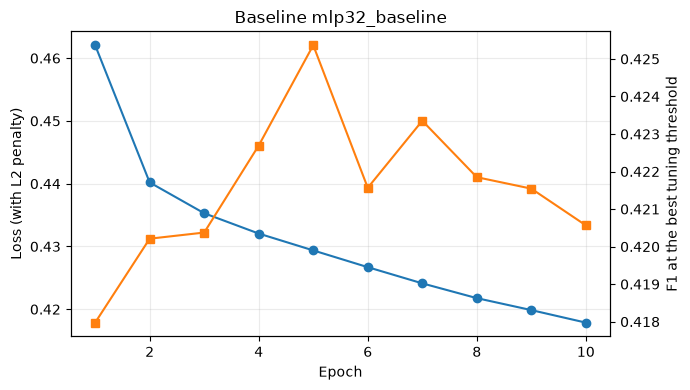

In [4]:
epochs = [row["epoch"] for row in history]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, [row["training_batch_loss"] for row in history], marker="o", label="Training loss")
ax2 = ax.twinx()
ax2.plot(epochs, [row["selection_score"] for row in history], marker="s", color="tab:orange", label="Tuning F1")
ax.set(xlabel="Epoch", ylabel="Loss (with L2 penalty)", title=f"Baseline {member_name}")
ax2.set_ylabel("F1 at the best tuning threshold")
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(RESULT_DIR / "baseline_nn_courbe.png", dpi=150)
plt.show()



The submission file of the network contains the **109,379 predictions**, in the same order and with the same ids as `x_test.csv`, with labels `-1/+1`. It is written with `create_csv_submission` from `helpers.py`.


In [5]:
info = json.loads((RESULT_DIR / "submission_info.json").read_text())
print("File:", RESULT_DIR / "submission_nn.csv")
print("Predictions:", info["rows"])
print("Predicted sick:", info["positives"])
print("Submitted to AIcrowd:", info["submitted"])


File: /Users/firyalelalj/ML_CS/Machine_Learning_CS/figures/nn/submission_nn.csv
Predictions: 109379
Predicted sick: 11441
Submitted to AIcrowd: False
